# MATPLOTLIB MASTERY — NOTEBOOK 8
## Chapters 66–75: Data Leakage Visualization → Data Drift → Outlier Detection → Missing Data → Categorical Data → Time-Series → Rolling Statistics → Multi-Panel Time Series → Professional EDA Notebook → Matplotlib Debugging

Continuing directly from Notebook 7.

### Progress Tracker (this notebook)
- [x] Chapter 66 — Data Leakage Visualization
- [x] Chapter 67 — Data Drift Visualization
- [x] Chapter 68 — Outlier Detection
- [x] Chapter 69 — Missing Data Visualization
- [x] Chapter 70 — Categorical Data Visualization
- [x] Chapter 71 — Time-Series Visualization
- [x] Chapter 72 — Rolling Statistics Visualization
- [x] Chapter 73 — Multi-Panel Time Series
- [x] Chapter 74 — Professional EDA Notebook (complete worked example)
- [x] Chapter 75 — Matplotlib Debugging (15 problems)


In [1]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
np.random.seed(42)


---
# CHAPTER 66 — DATA LEAKAGE VISUALIZATION

## 1. Concept
Data leakage occurs when information that wouldn't be available at real prediction time "leaks" into training — often producing a suspiciously perfect model. Visualization is one of the fastest ways to catch it, **before** it silently inflates a model's reported performance.

## 2. Why It Matters
A leaked feature can make a model look excellent in testing and then fail badly (or be unusable) in production, because the leaked signal simply won't exist at real inference time. Catching this via a quick visual check, before investing in a full modeling pipeline, is a high-leverage habit.

## Visual Signatures of Common Leakage Types


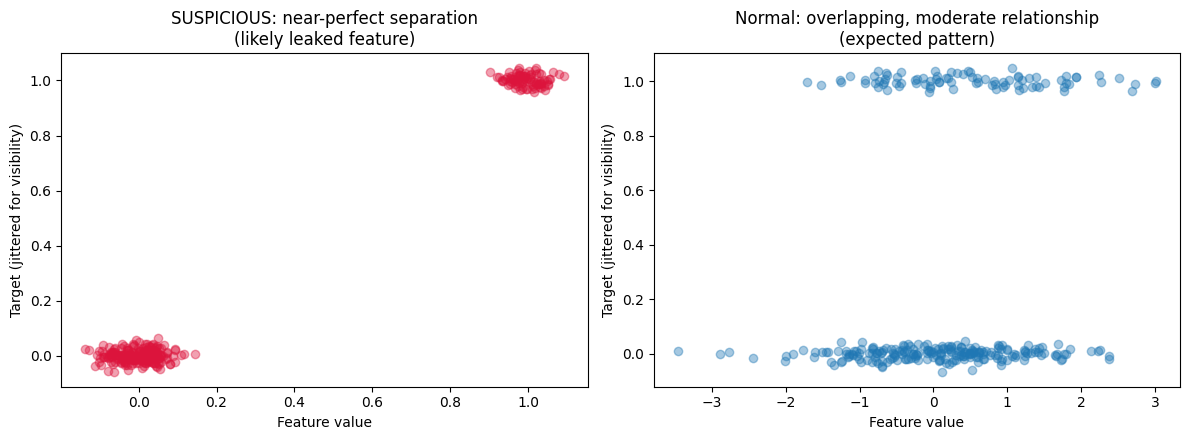

In [2]:
np.random.seed(50)
n_leak = 300
target_leak = np.random.choice([0, 1], n_leak, p=[0.7, 0.3])

# Simulate a LEAKED feature: near-perfectly derived from the target itself (e.g., "was_flagged_by_manual_review")
leaked_feature = target_leak + np.random.normal(0, 0.05, n_leak)

# Simulate a NORMAL, non-leaked feature with a real but moderate relationship to the target
normal_feature = target_leak * 0.5 + np.random.normal(0, 1, n_leak)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].scatter(leaked_feature, target_leak + np.random.normal(0, 0.02, n_leak), alpha=0.4, color="crimson")
axes[0].set_title("SUSPICIOUS: near-perfect separation\n(likely leaked feature)")
axes[0].set_xlabel("Feature value")
axes[0].set_ylabel("Target (jittered for visibility)")

axes[1].scatter(normal_feature, target_leak + np.random.normal(0, 0.02, n_leak), alpha=0.4, color="tab:blue")
axes[1].set_title("Normal: overlapping, moderate relationship\n(expected pattern)")
axes[1].set_xlabel("Feature value")
axes[1].set_ylabel("Target (jittered for visibility)")

plt.tight_layout()
plt.show()


### Interpretation
The left panel shows the classic leakage red flag: the two target classes' feature values are **almost perfectly separated** with virtually no overlap — a pattern that real-world, honestly-predictive features essentially never produce this cleanly (genuine predictive signal is almost always noisy and overlapping, as in the right panel). Any feature producing a scatter/histogram this cleanly separated deserves an immediate manual investigation: does this feature's value get determined *before* or *after* the outcome it's meant to predict?

### Additional Leakage-Detection Visualizations
- **Feature importance dominated by one feature**: if a single feature's importance (Chapter 59) is dramatically higher than every other feature combined, investigate it specifically — it's a common leakage signature.
- **Near-perfect ROC/PR curves** (Chapters 54–55): an AUC suspiciously close to 1.0 on a problem that's inherently difficult (e.g., predicting customer churn a year in advance) should trigger suspicion rather than celebration.
- **Correlation matrix** (Chapter 45): a feature correlating at ±0.98+ with the target is worth investigating for leakage before assuming it's simply an excellent predictor.

### Common Mistakes
- Treating unusually strong model performance as purely good news without first checking for leakage — the single most common and costly ML engineering mistake this course covers.
- Not checking *when*, chronologically or causally, each feature's value would actually be known relative to the prediction target — the root cause of most temporal leakage.

### Best Practices
- Whenever a model's performance looks "too good," visualize the top few features' individual relationships with the target (scatter/histogram by class) before trusting the result.
- Explicitly audit every feature's data-availability timing relative to the prediction moment, especially for any feature engineered from data that spans the same time window as the target.

### Interview Insight
**Q: Your fraud-detection model achieves 99.8% ROC-AUC on a problem domain experts say is genuinely difficult. What's your first move before celebrating?**
A: Suspect data leakage first. Check feature importances for any single feature dominating disproportionately, visualize that feature's distribution split by target class (looking for the near-perfect-separation pattern), and audit whether every feature's value would actually be available and correctly timestamped at real prediction time — not, for instance, computed using information that only exists *after* the fraud was already confirmed (a classic temporal leakage pattern).

### Mini Exercise
Regenerate `leaked_feature` with a wider noise term (`np.random.normal(0, 0.3, n_leak)` instead of `0.05`) and observe at what noise level the separation starts to look more like a "normal, genuinely predictive feature" rather than an obvious leak — illustrating that leakage detection is a matter of degree, not a hard binary rule.

### Quiz (Chapter 66)
1. What's the key visual signature that distinguishes a likely-leaked feature from a genuinely predictive one?
2. Why should "too good to be true" model performance trigger a leakage check before celebration?
3. Name two other visualization-based leakage detection signals besides a single feature's scatter/histogram.


---
# CHAPTER 67 — DATA DRIFT VISUALIZATION

## 1. Concept
Data drift occurs when a production model's **input feature distributions** shift away from what the model was originally trained on — visualized by directly overlaying the training distribution against the current production distribution for each monitored feature.

## 2. Why It Matters
A model's accuracy can silently degrade in production purely because the world changed (new customer behavior, a new product line, a seasonal shift) — visual drift monitoring is a standard, essential component of any production ML monitoring system, catching this before it's discovered via a business-metric drop.


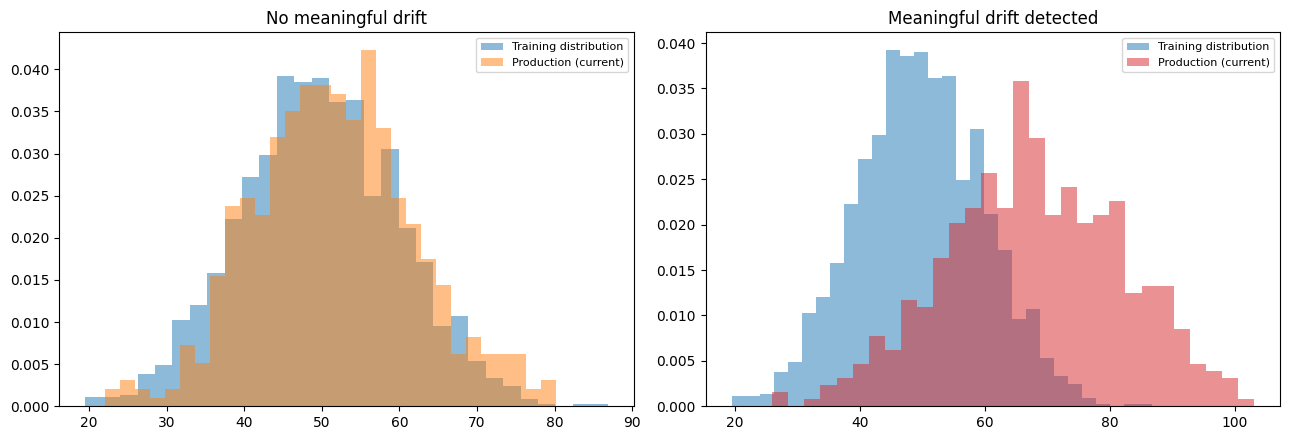

In [3]:
np.random.seed(60)
training_dist = np.random.normal(50, 10, 2000)
production_dist_ok = np.random.normal(51, 10.5, 500)      # minor, expected fluctuation
production_dist_drifted = np.random.normal(68, 14, 500)   # meaningful drift

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].hist(training_dist, bins=30, density=True, alpha=0.5, label="Training distribution", color="tab:blue")
axes[0].hist(production_dist_ok, bins=30, density=True, alpha=0.5, label="Production (current)", color="tab:orange")
axes[0].set_title("No meaningful drift")
axes[0].legend(fontsize=8)

axes[1].hist(training_dist, bins=30, density=True, alpha=0.5, label="Training distribution", color="tab:blue")
axes[1].hist(production_dist_drifted, bins=30, density=True, alpha=0.5, label="Production (current)", color="tab:red")
axes[1].set_title("Meaningful drift detected")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()


### Line-by-Line Explanation
- `density=True` on both histograms is **mandatory** here, exactly as established in Chapter 19 — training and production sample sizes almost always differ (here 2000 vs 500), and comparing raw counts would confound "how much data we happened to collect" with "how different the distributions actually are."
- The two-panel comparison (no drift vs. genuine drift, side by side) trains the eye on what a **meaningful** shift actually looks like versus normal sampling noise — an important calibration exercise, since not every small histogram difference is worth an alert.

### A Time-Series View of Drift (Monitoring Over Multiple Periods)


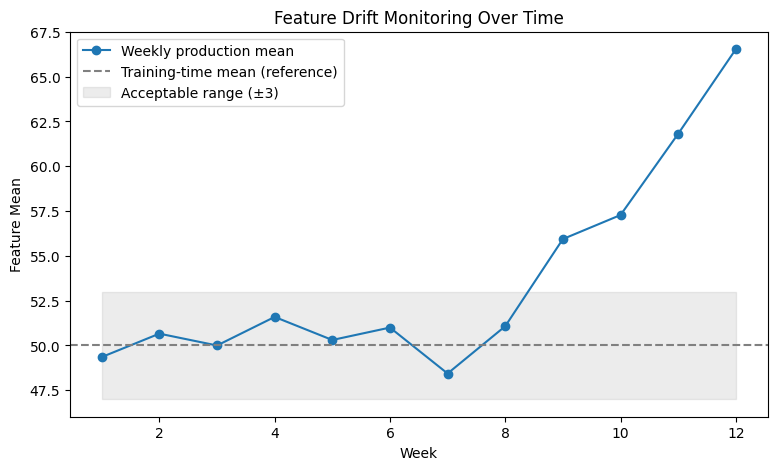

In [4]:
np.random.seed(61)
weeks = np.arange(1, 13)
weekly_means = 50 + np.concatenate([np.zeros(6), np.linspace(0, 15, 6)]) + np.random.normal(0, 1.5, 12)
training_mean_ref = 50

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(weeks, weekly_means, marker="o", color="tab:blue", label="Weekly production mean")
ax.axhline(training_mean_ref, color="gray", linestyle="--", label="Training-time mean (reference)")
ax.fill_between(weeks, training_mean_ref - 3, training_mean_ref + 3, alpha=0.15, color="gray", label="Acceptable range (±3)")

ax.set_xlabel("Week")
ax.set_ylabel("Feature Mean")
ax.set_title("Feature Drift Monitoring Over Time")
ax.legend()
plt.show()


### Interpretation
The second chart directly reuses the `fill_between` "acceptable range" band idea from Chapter 26/27 — but here as a **monitoring tool**: the weekly production mean tracking within the shaded band (weeks 1–6) is healthy; the point where it visibly and persistently exits the band (around week 7 onward) is the actionable drift-detection signal, telling an ML engineering team exactly when to investigate and likely retrain.

### Common Mistakes
- Comparing raw counts instead of densities when training/production sample sizes differ — the same Chapter 19 mistake, now in a monitoring context where it's even more consequential (could trigger false drift alarms, or mask real ones).
- Treating any small week-to-week fluctuation as "drift" — normal sampling variation always exists; an explicit acceptable-range band (as shown) helps distinguish genuine drift from noise.
- Monitoring only the target/output distribution and not individual **input feature** distributions — input drift often precedes and causes output/performance drift, so it's the earlier, more actionable warning signal.

### Best Practices
- Monitor key input feature distributions on a regular cadence (daily/weekly), not just aggregate model performance metrics, since feature drift is an earlier warning sign.
- Define and visualize an explicit "acceptable range" band rather than relying on eyeballing raw fluctuation.
- Always use `density=True` (or an equivalent normalized comparison) when comparing training and production distributions of different sample sizes.

### Interview Insight
**Q: How would you set up ongoing visual monitoring to catch data drift before it causes a measurable drop in model performance?**
A: Track key input feature distributions (means, or full histograms) on a regular cadence, plotted over time against the training-time reference value with an explicit acceptable-range band (e.g., derived from the training-time distribution's own natural variation). This monitors the *cause* (input drift) rather than only the *symptom* (performance drop), giving an earlier warning — by the time aggregate model accuracy visibly drops, meaningful business damage may have already occurred.

### Mini Exercise
Regenerate the weekly drift-monitoring chart with the drift happening more gradually (a smaller, slower `np.linspace` ramp) and observe how much later the point where the line clearly and persistently exits the acceptable-range band becomes, compared to the sharper drift simulated above.

### Quiz (Chapter 67)
1. Why must training-vs-production distribution comparisons always be density-normalized?
2. Why should feature-level (input) drift be monitored, not just target/performance drift?
3. What visual device helps distinguish genuine drift from normal week-to-week noise?


---
# CHAPTER 68 — OUTLIER DETECTION

## 1. Concept
This chapter consolidates the outlier-detection techniques already built across the course — box plots (Ch 22), scatter plots (Ch 13), histograms (Ch 19), and time series (Ch 71) — into a single applied workflow, with explicit emphasis on the judgment call this course has flagged repeatedly: **outlier vs. valid rare observation**.

## 2. Why It Matters
Automatically deleting every flagged "outlier" is one of the most common, quietly damaging mistakes in applied data science — some outliers are data errors (delete/fix), and some are exactly the rare, high-value events an analysis or model most needs to capture (e.g., the single biggest fraud case, the one customer whose complaint reveals a major product bug).


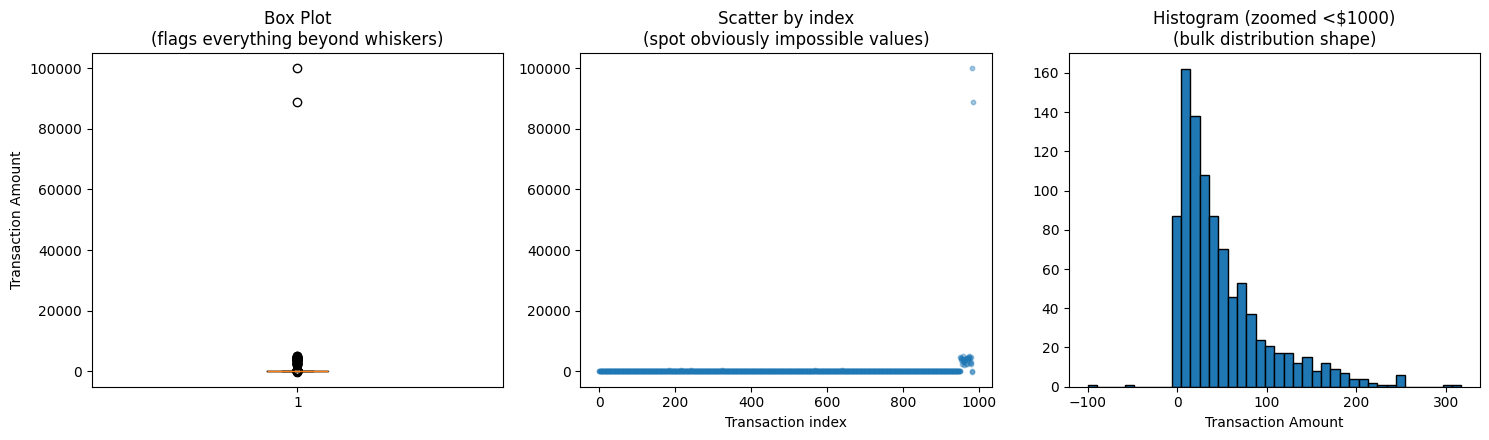

Negative values (impossible, definite errors): 2
Extreme values > $10,000 (investigate individually): 2


In [5]:
np.random.seed(70)
transaction_amounts = np.concatenate([
    np.random.exponential(50, 950),          # ordinary transactions
    np.random.uniform(2000, 5000, 30),       # genuinely large, legitimate transactions
    np.array([-100, -50, 99999, 88888]),     # DATA ERRORS: negative amounts, impossible values
])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

axes[0].boxplot(transaction_amounts, vert=True)
axes[0].set_title("Box Plot\n(flags everything beyond whiskers)")
axes[0].set_ylabel("Transaction Amount")

axes[1].scatter(range(len(transaction_amounts)), transaction_amounts, alpha=0.4, s=10, color="tab:blue")
axes[1].set_title("Scatter by index\n(spot obviously impossible values)")
axes[1].set_xlabel("Transaction index")

axes[2].hist(transaction_amounts[transaction_amounts < 1000], bins=40, color="tab:blue", edgecolor="black")
axes[2].set_title("Histogram (zoomed <$1000)\n(bulk distribution shape)")
axes[2].set_xlabel("Transaction Amount")

plt.tight_layout()
plt.show()

print("Negative values (impossible, definite errors):", (transaction_amounts < 0).sum())
print("Extreme values > $10,000 (investigate individually):", (transaction_amounts > 10000).sum())


### Line-by-Line Explanation
- The synthetic data deliberately mixes **three distinct categories**: ordinary transactions, genuinely large-but-legitimate transactions ($2,000–$5,000), and outright impossible values (negative amounts, a $99,999 value clearly outside any plausible range) — mirroring a realistic real-world mix that a single "remove all outliers" rule would handle badly.
- The scatter-by-index panel (x = row position, not a meaningful feature) is a simple, effective technique specifically for spotting **impossible/erroneous** values (negative amounts, absurd magnitudes) that stand out obviously regardless of the rest of the distribution's shape.
- Explicitly counting negative values (`< 0`, unambiguously errors for a transaction amount) separately from merely large values (`> 10000`, which need individual judgment) operationalizes the "not all outliers are the same" principle into concrete, different next actions.

### The Decision Framework
| Outlier type | Example | Action |
|---|---|---|
| **Impossible / invalid** | Negative transaction amount, age of 200 | Fix or remove — these are data quality errors, not real observations |
| **Data entry error** | A misplaced decimal (e.g., $50,000 instead of $500) | Investigate and correct if identifiable, otherwise remove |
| **Genuine rare event** | A legitimately large but real transaction | **Keep** — often the most business-relevant data point in the set |
| **Valid but influential** | A point that disproportionately affects a fitted model (e.g., high leverage in linear regression) | Keep in the data, but be aware of and report its influence on any model/statistic |

### Common Mistakes
- Applying a single automatic rule (e.g., "remove everything beyond 1.5×IQR") without any manual inspection — silently discards genuine, often important, rare-but-real events.
- Not distinguishing "impossible" (negative transaction amount) from "merely unusual" (a large but plausible transaction) — these require entirely different actions.
- Removing outliers **before** doing any visualization of the raw data — always look first, decide with intention second.

### Best Practices
- Always visualize outliers before deciding their fate — never apply an automated removal rule blindly.
- Explicitly separate "definitely impossible" values (which can usually be safely fixed/removed) from "unusual but plausible" values (which need individual investigation or should often simply be kept).
- Document any outlier-handling decisions explicitly in analysis/model documentation — this is a judgment call, and the reasoning should be traceable.

### Interview Insight
**Q: A box plot flags 40 "outliers" in your transaction dataset. Walk through how you'd decide what to do with each.**
A: First separate genuinely impossible values (negative amounts, values clearly outside any plausible real-world range) — these are almost certainly data errors and can typically be corrected or removed with confidence. For the remaining flagged points that are merely large-but-plausible, investigate individually (or in aggregate, by checking whether they share some identifiable pattern like a specific customer type or time period) rather than removing them wholesale — many are likely genuine, valuable rare events that the analysis specifically needs to retain, not artifacts to discard.

### Mini Exercise
Compute what fraction of the whole dataset the box plot's "outlier" flags represent (`len(flagged) / len(transaction_amounts)`), and compare that fraction to the fraction that are *actually* impossible/erroneous (negative or absurdly large) — illustrating that "flagged by the box plot" and "should be removed" are not the same set.

### Quiz (Chapter 68)
1. What's the key distinction this chapter draws between different types of flagged outliers?
2. Why is a scatter-by-index plot useful specifically for spotting impossible/erroneous values?
3. Why should outlier removal decisions always be documented explicitly?


---
# CHAPTER 69 — MISSING DATA VISUALIZATION

## 1. Concept
Beyond a simple missing-count-per-column bar (Chapter 41), understanding **missingness patterns** — whether missing values cluster together, correlate with other columns, or trend over time — is essential for choosing the right handling strategy (drop, impute, or flag-as-a-feature).

## 2. Why It Matters
Missing values are not always "missing completely at random" — sometimes missingness itself carries information (e.g., a customer skipping an income field might correlate with income level itself), and visualizing the *pattern* of missingness (not just the count) is how you'd discover that.


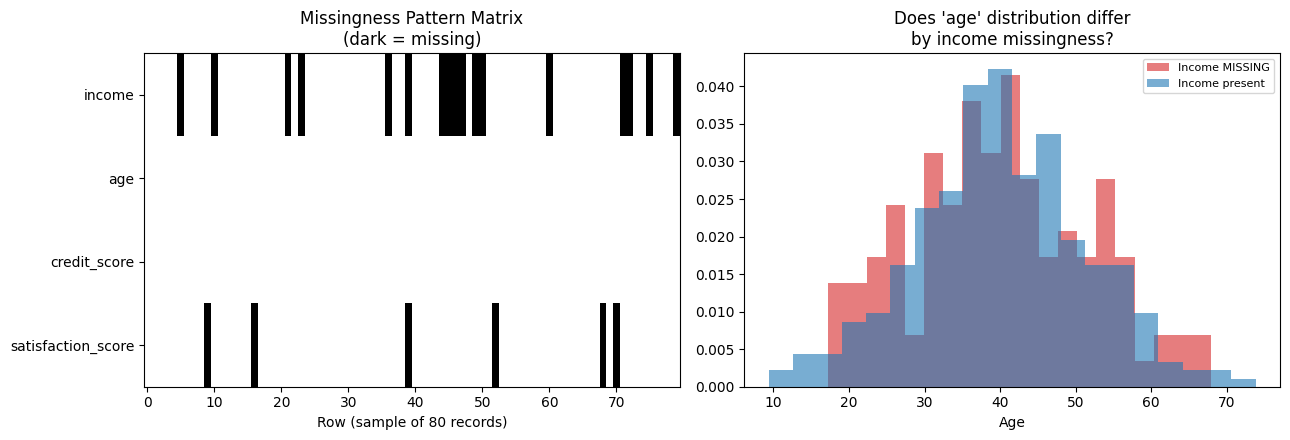

Missing % by column:
income                28.5
age                    0.0
credit_score           0.0
satisfaction_score     9.8
dtype: float64


In [6]:
np.random.seed(80)
n_missing = 400
missing_df = pd.DataFrame({
    "income": np.random.normal(60000, 15000, n_missing),
    "age": np.random.normal(40, 12, n_missing),
    "credit_score": np.random.normal(680, 60, n_missing),
    "satisfaction_score": np.random.normal(7, 1.5, n_missing),
})

# Simulate NON-random missingness: higher earners are more likely to skip reporting income
skip_prob = 1 / (1 + np.exp(-(missing_df["income"] - 60000) / 10000))   # sigmoid: higher income -> more likely missing
missing_mask = np.random.rand(n_missing) < skip_prob * 0.5
missing_df.loc[missing_mask, "income"] = np.nan

# Simulate a SEPARATE, unrelated column with random missingness
random_missing_mask = np.random.rand(n_missing) < 0.08
missing_df.loc[random_missing_mask, "satisfaction_score"] = np.nan

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Panel 1: missingness pattern matrix (rows=sample of records, cols=features; dark = missing)
sample_rows = missing_df.head(80)
missing_matrix = sample_rows.isna().values.astype(int)
im = axes[0].imshow(missing_matrix.T, cmap="gray_r", aspect="auto", interpolation="nearest")
axes[0].set_yticks(range(len(missing_df.columns)))
axes[0].set_yticklabels(missing_df.columns)
axes[0].set_xlabel("Row (sample of 80 records)")
axes[0].set_title("Missingness Pattern Matrix\n(dark = missing)")

# Panel 2: does missingness in 'income' relate to the OBSERVED age distribution? (a common leakage-adjacent check)
axes[1].hist(missing_df.loc[missing_df["income"].isna(), "age"], bins=20, alpha=0.6, density=True, label="Income MISSING", color="tab:red")
axes[1].hist(missing_df.loc[missing_df["income"].notna(), "age"], bins=20, alpha=0.6, density=True, label="Income present", color="tab:blue")
axes[1].set_xlabel("Age")
axes[1].set_title("Does 'age' distribution differ\nby income missingness?")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

print("Missing % by column:")
print((missing_df.isna().mean() * 100).round(1))


### Line-by-Line Explanation
- `ax.imshow(missing_matrix.T, cmap="gray_r", interpolation="nearest")` — directly reuses Chapter 47's rule (`interpolation="nearest"` for exact discrete values — here, missing=1/present=0 is about as discrete as data gets) to render a full missingness pattern across many rows and columns at once, letting you visually spot whether missing values in different columns tend to co-occur in the same rows (a pattern a simple per-column count bar, from Chapter 41, cannot reveal).
- Panel 2 directly investigates **why** income might be missing, by comparing the age distribution of records with vs. without missing income — `density=True` again required (group sizes differ). This is the visual equivalent of testing whether missingness is "at random" with respect to another observed variable — if the two histograms look meaningfully different, missingness is *not* random and needs to be handled more carefully than simple mean-imputation would assume.

### Interpretation
If Panel 2's two histograms look near-identical, missing income doesn't obviously relate to age — but recall this dataset was specifically constructed so that missingness relates to income *itself* (higher earners skip more often), which is a pattern that can't be directly visualized against the income column (since that's exactly the missing data) but could be indirectly suspected via other observed proxies, or via domain knowledge ("people are often reluctant to report high incomes") — an important reminder that some missingness mechanisms require domain reasoning, not just visualization, to fully diagnose.

### Common Mistakes
- Assuming all missing values are "missing completely at random" (MCAR) by default and applying simple mean/median imputation without checking — if missingness correlates with the target or other features (as simulated here), naive imputation can introduce meaningful bias.
- Only checking missing-count-per-column (Chapter 41) and never the missingness *pattern* across rows — misses co-occurrence structure that a full pattern matrix reveals.
- Not considering "missing" itself as potentially informative — sometimes the best handling is to keep a missing-value **indicator** as its own feature rather than only imputing a substitute value, precisely because the missingness itself may carry signal (as in this income example).

### Best Practices
- Visualize both the per-column missing count (Chapter 41) AND the cross-row missingness pattern (this chapter) before choosing a handling strategy.
- When feasible, check whether missingness in one column relates to other **observed** variables — a meaningful relationship is evidence against pure MCAR and should inform a more careful imputation strategy (or an added "was_missing" indicator feature).

### Interview Insight
**Q: Why might blindly mean-imputing a column with missing values introduce bias, and how would you check for this risk visually?**
A: If missingness is not purely random — for example, if higher earners are more likely to skip reporting income — mean imputation systematically pulls the imputed values toward the *overall* mean, which can be quite different from what those specific (systematically-missing) records' true values likely were, biasing any downstream analysis or model. To check, compare other observed variables' distributions between records with missing vs. present values for the column in question (as in Panel 2) — a meaningful difference between those two groups is evidence that the missingness isn't random and needs more careful handling than naive imputation, such as a missing-value indicator feature or a more sophisticated (e.g., model-based) imputation approach.

### Mini Exercise
Recreate Panel 2 using `credit_score` instead of `age` as the variable compared across the income-missing vs. income-present groups.

### Quiz (Chapter 69)
1. What does the missingness pattern matrix reveal that a simple per-column missing count cannot?
2. Why might missingness NOT be "completely at random," and why does that matter for imputation strategy?
3. What alternative to simple imputation exists specifically when missingness itself may be informative?


---
# CHAPTER 70 — CATEGORICAL DATA VISUALIZATION

## 1. Concept
This chapter consolidates categorical-visualization techniques already covered (bar charts, Ch 15–16; grouped/stacked, Ch 17–18) specifically around the challenges of **high cardinality** (many distinct categories) and **long-tail** distributions (a few dominant categories, many rare ones).

## 2. Why It Matters
Real categorical features (product SKU, city, free-text-derived tags) often have far too many distinct values to show individually — this chapter formalizes the "top-N + Other" pattern that professional dashboards rely on.


In [7]:
np.random.seed(90)
n_cat = 2000
# Simulate a long-tail categorical variable: a few common categories, a long tail of rare ones
top_categories = ["Electronics", "Clothing", "Home", "Books", "Sports"]
tail_categories = [f"Niche_{i}" for i in range(40)]   # 40 rare categories
probs_top = [0.30, 0.22, 0.18, 0.12, 0.08]
probs_tail = [0.10 / 40] * 40
all_cats = top_categories + tail_categories
all_probs = probs_top + probs_tail
category_data = np.random.choice(all_cats, size=n_cat, p=all_probs)

counts = pd.Series(category_data).value_counts()
print("Total distinct categories:", len(counts))
print(counts.head(8))


Total distinct categories: 45
Electronics    608
Clothing       438
Home           384
Books          228
Sports         154
Niche_2         11
Niche_34        10
Niche_15         9
Name: count, dtype: int64


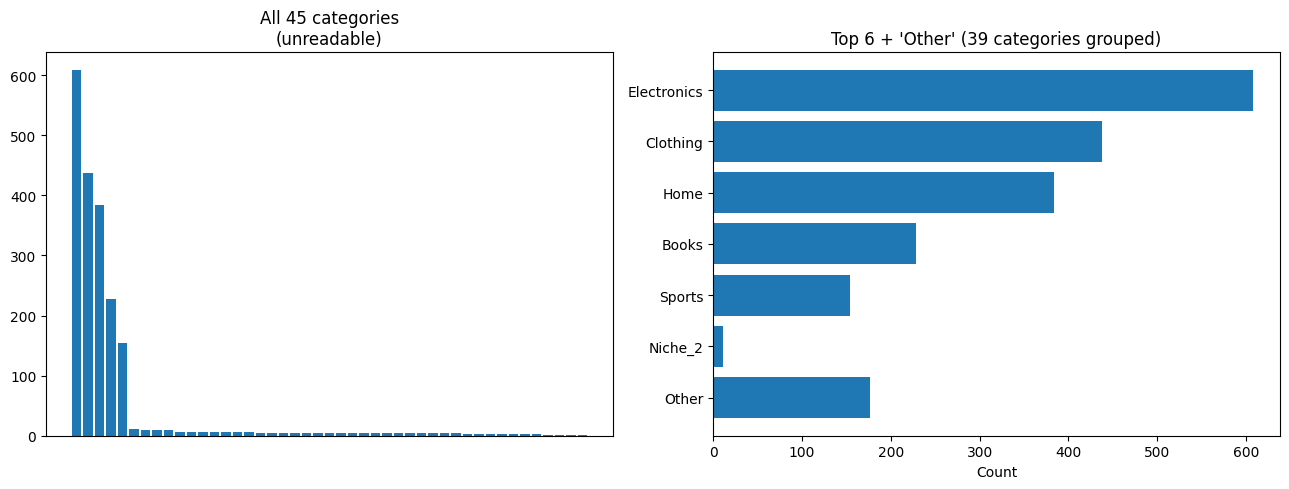

In [8]:
top_n = 6
top_counts = counts.head(top_n)
other_count = counts.iloc[top_n:].sum()

grouped_counts = pd.concat([top_counts, pd.Series({"Other": other_count})])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# WITHOUT grouping: unreadable, 45 bars
axes[0].bar(range(len(counts)), counts.values, color="tab:blue")
axes[0].set_title(f"All {len(counts)} categories\n(unreadable)")
axes[0].set_xticks([])

# WITH top-N + Other grouping
axes[1].barh(grouped_counts.index[::-1], grouped_counts.values[::-1], color="tab:blue")
axes[1].set_title(f"Top {top_n} + 'Other' ({len(counts) - top_n} categories grouped)")
axes[1].set_xlabel("Count")

plt.tight_layout()
plt.show()


### Line-by-Line Explanation
- `counts.head(top_n)` / `counts.iloc[top_n:].sum()` — the standard Pandas idiom for "top N individually, everything else summed into a single Other bucket" — this pattern belongs in essentially every categorical EDA involving more than ~10–15 distinct values.
- The left panel is deliberately included as a **negative example**: 45 unlabeled, unreadable bars — a direct, visual demonstration of exactly the failure mode Chapter 15's "too many categories" warning described in the abstract.
- The right panel switches to `barh` (Chapter 16) for readability, and the explicit "Other (N categories grouped)" label is essential — it tells the reader precisely how much detail was compressed away, rather than silently hiding it.

### Interpretation
The top-N+Other view makes the actually-important structure ("Electronics dominates, followed by a gradual decline through the next few categories, with a genuinely long tail of niche categories collectively still meaningful") legible in a way the raw 45-bar chart cannot, while the explicit "Other" label preserves honesty about what's been aggregated away rather than pretending those categories don't exist.

### Common Mistakes
- Silently dropping the long tail entirely instead of summing it into a labeled "Other" bucket — loses the (often still substantial) aggregate size of the tail, which can itself be a meaningful business fact ("niche products collectively represent 10% of transactions").
- Choosing `top_n` arbitrarily without checking how much of the total it actually captures — always check what percentage of the data the shown categories vs. "Other" represent (a Pareto-style check).
- Sorting the top-N alphabetically instead of by count — defeats the purpose of prioritizing the categories that matter most.

### Best Practices
- Default to top-10 (or top-N such that "Other" captures a clearly minority share, often via a quick Pareto check) + an explicitly labeled "Other" bucket for any categorical variable with more than ~10–15 distinct values.
- State the "Other" bucket's category count in its label, as done above, for full transparency about what's been compressed.

### Interview Insight
**Q: A categorical feature has 200 distinct values. How would you visualize its frequency distribution?**
A: Compute value counts, sort descending, show the top N individually (commonly top-10, or wherever a quick cumulative-percentage check shows most of the data is captured) as a horizontal bar chart for label readability, and sum everything beyond that into a single, explicitly-labeled "Other (N categories)" bucket — never silently drop the tail or attempt to show all 200 bars, which would be unreadable regardless of chart type.

### Mini Exercise
Compute what percentage of the full dataset the top 6 categories actually represent (`top_counts.sum() / counts.sum()`), and use that to justify (or adjust) the choice of `top_n=6` used above.

### Quiz (Chapter 70)
1. What's the standard pattern for visualizing a high-cardinality categorical variable?
2. Why must the "Other" bucket be explicitly labeled with how many categories it contains?
3. Why is `barh` generally preferred over `bar` once you're down to a manageable top-N + Other view with potentially long category names?


---
# CHAPTER 71 — TIME-SERIES VISUALIZATION

## 1. Concept
Beyond basic date-axis formatting (Chapter 38), professional time-series visualization specifically diagnoses **trend**, **seasonality**, **spikes/drops**, and **missing periods** — the standard structural components analysts decompose a time series into.

## 2. Why It Matters
Recognizing these components visually is the first step before any forecasting or anomaly-detection modeling — and often reveals the answer to a business question directly, without needing a model at all.


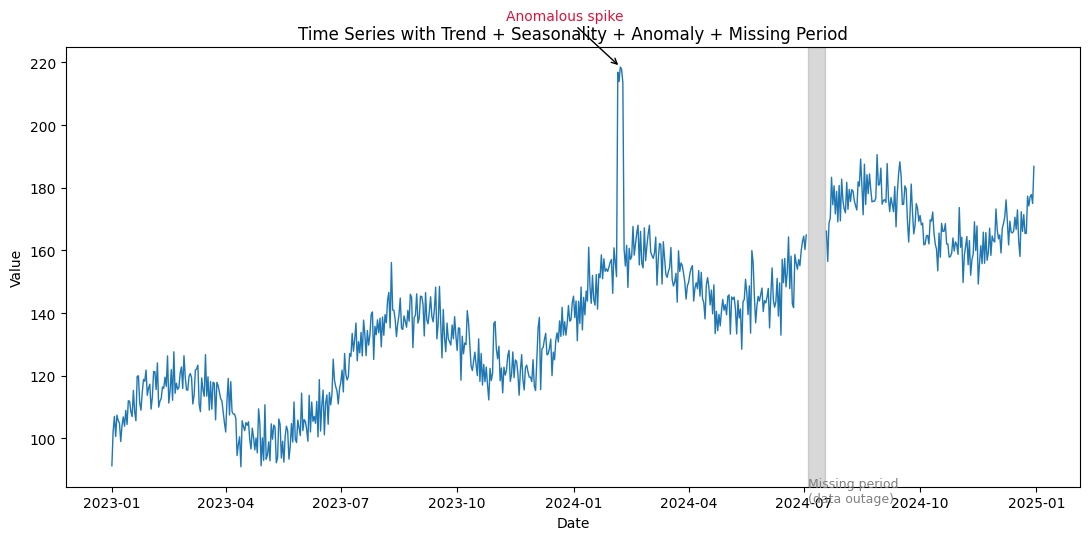

In [9]:
np.random.seed(100)
dates_ts = pd.date_range("2023-01-01", periods=730, freq="D")
trend = np.linspace(100, 180, 730)
seasonality = 15 * np.sin(2 * np.pi * np.arange(730) / 365.25 * 2)   # ~biannual seasonal pattern
noise = np.random.normal(0, 5, 730)
spike = np.zeros(730)
spike[400:405] = 60   # a sudden anomalous spike
values_ts = trend + seasonality + noise + spike

ts_series = pd.Series(values_ts, index=dates_ts)
# Simulate a missing period (e.g., a data collection outage)
ts_series.iloc[550:565] = np.nan

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.plot(ts_series.index, ts_series.values, color="tab:blue", linewidth=1)

# Annotate the components programmatically (Ch 33's pattern)
spike_idx = np.nanargmax(values_ts)
ax.annotate("Anomalous spike", xy=(dates_ts[spike_idx], values_ts[spike_idx]),
            xytext=(dates_ts[spike_idx] - pd.Timedelta(days=90), values_ts[spike_idx] + 15),
            arrowprops=dict(facecolor="crimson", arrowstyle="->"), color="crimson")

missing_start, missing_end = dates_ts[550], dates_ts[564]
ax.axvspan(missing_start, missing_end, color="gray", alpha=0.3)
ax.annotate("Missing period\n(data outage)", xy=(missing_start, ax.get_ylim()[0]),
            xytext=(missing_start, ax.get_ylim()[0] - 5), color="gray", fontsize=9, ha="left")

ax.set_title("Time Series with Trend + Seasonality + Anomaly + Missing Period")
ax.set_xlabel("Date")
ax.set_ylabel("Value")
plt.tight_layout()
plt.show()


### Line-by-Line Explanation
- `ax.axvspan(start, end, color="gray", alpha=0.3)` — a new, time-series-specific pattern: shades a **vertical band across the full height of the Axes** between two x-values, the standard way to visually flag a date range (outages, holidays, promotional periods, training-vs-test split boundaries) rather than a single point.
- `np.nanargmax(values_ts)` — the `nan`-aware version of `np.argmax` (Chapter 33), required here since the series contains genuine missing values and a plain `argmax` would error or behave unexpectedly on `NaN`-containing arrays.
- Matplotlib's line plot naturally shows a visible **gap** where `ts_series` is `NaN` (Pandas' `NaN` values are not connected by `ax.plot()`) — this is actually the *correct*, honest default behavior: it would be misleading to interpolate a line straight across a genuine data-collection outage without explicitly marking it as such.

### Interpretation
- **Trend**: the overall upward drift across the full 2 years is visible even through the noise/seasonality — this is the kind of long-run structural change a business would want flagged (e.g., "underlying demand is growing").
- **Seasonality**: the wave-like oscillation repeating roughly twice a year.
- **Anomaly**: the sharp, brief spike stands out clearly against the surrounding noise level — annotated explicitly rather than left for the reader to spot unaided.
- **Missing period**: shaded explicitly, so a reader doesn't mistake the gap for "the value genuinely dropped to zero" or, worse, fail to notice it was ever missing at all.

### Common Mistakes
- Interpolating straight across a missing period without any visual indication — makes a data outage indistinguishable from genuine (and very different) real values.
- Not annotating a known anomaly/incident on the chart, forcing every viewer to rediscover it from scratch rather than benefiting from already-known context.
- Failing to check for and account for seasonality before interpreting a shorter time window as a "trend" — a few weeks of a seasonal upswing can easily be mistaken for sustained underlying growth if the seasonal pattern isn't already understood.

### Best Practices
- Use `ax.axvspan()` to flag any known date range of interest (outages, campaigns, policy changes) directly on the chart.
- Annotate known anomalies explicitly rather than assuming they're self-evident.
- Always check for and account for seasonality before drawing trend conclusions from a short window.

### Interview Insight
**Q: You need to present a chart showing a data pipeline outage that caused 15 days of missing data. How do you represent this rather than just leaving a gap?**
A: Leave the actual line gap (don't interpolate across it — that would fabricate data that was never observed) but explicitly shade the affected date range with `ax.axvspan()` and annotate it (e.g., "Data outage — pipeline incident") so a viewer immediately understands *why* there's a gap rather than mistaking it for missing data of unknown cause, or worse, not noticing the gap's significance at all.

### Mini Exercise
Add a second `ax.axvspan()` marking a hypothetical "product launch" date range somewhere in the trending-upward portion of the series, styled in a different color (e.g., green) from the gray missing-period band, to practice distinguishing multiple types of annotated regions on one chart.

### Quiz (Chapter 71)
1. What Matplotlib function shades a full-height vertical band between two x-values, and what's it typically used for?
2. Why shouldn't you interpolate a line across a genuine data-collection outage?
3. What NumPy function is the NaN-safe version of `argmax`, and why is it needed here?


---
# CHAPTER 72 — ROLLING STATISTICS VISUALIZATION

## 1. Concept
Pandas' `.rolling(window).mean()` (and `.std()`, `.median()`, etc.) computes a moving statistic over a sliding window — overlaying this on the raw series (a pattern already previewed in Chapter 4's Mini Exercise) smooths out short-term noise to reveal the underlying trend more clearly.

## 2. Why It Matters
Raw daily/high-frequency data is often too noisy to visually assess trend directly — a rolling average is the standard, simple denoising technique used before any more sophisticated time-series decomposition or modeling.


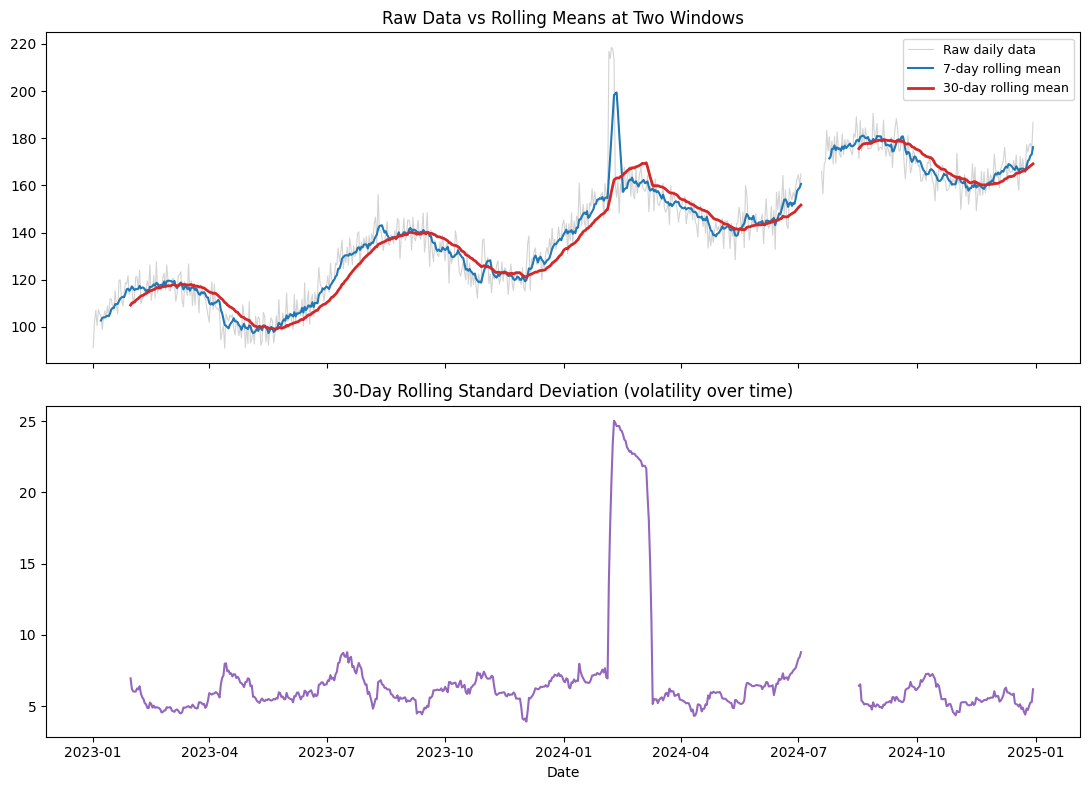

In [10]:
rolling_mean_7 = ts_series.rolling(7).mean()
rolling_mean_30 = ts_series.rolling(30).mean()
rolling_std_30 = ts_series.rolling(30).std()

fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

axes[0].plot(ts_series.index, ts_series.values, color="lightgray", linewidth=0.8, label="Raw daily data")
axes[0].plot(rolling_mean_7.index, rolling_mean_7.values, color="tab:blue", linewidth=1.5, label="7-day rolling mean")
axes[0].plot(rolling_mean_30.index, rolling_mean_30.values, color="tab:red", linewidth=2, label="30-day rolling mean")
axes[0].set_title("Raw Data vs Rolling Means at Two Windows")
axes[0].legend(fontsize=9)

axes[1].plot(rolling_std_30.index, rolling_std_30.values, color="tab:purple")
axes[1].set_title("30-Day Rolling Standard Deviation (volatility over time)")
axes[1].set_xlabel("Date")

plt.tight_layout()
plt.show()


### Line-by-Line Explanation
- `ts_series.rolling(7).mean()` — for each date, averages the current value with the preceding 6 (a 7-value trailing window); the first 6 values of the result are `NaN` (not enough prior data yet to fill the window) — Matplotlib's line plot naturally skips these, producing a shorter visible line starting a few days after the raw data.
- Plotting a **short** window (7-day, closely tracks the raw data, still somewhat noisy) alongside a **longer** window (30-day, much smoother, lags real changes more) in the same panel directly illustrates the smoothing-vs-responsiveness tradeoff inherent to any rolling window choice — a wider window trades responsiveness to genuine recent changes for a smoother, lower-noise line.
- `rolling_std_30` — a rolling window isn't limited to the mean; a rolling **standard deviation** directly visualizes how the series' *volatility* itself changes over time, a genuinely different and complementary signal from the rolling mean's "level" view.

### Interpretation
The 7-day line still shows visible noise/seasonality bumps but tracks the raw data responsively; the 30-day line is much smoother and reveals the longer-run trend cleanly, but would be slower to reflect a genuine recent shift (e.g., a real regime change 5 days ago wouldn't be fully visible in the 30-day average yet). The rolling standard deviation panel separately reveals whether the series has become more or less volatile over time — a pattern invisible from the mean-based charts alone, and often itself a meaningful business or monitoring signal (e.g., rising volatility ahead of a known risk period).

### Common Mistakes
- Choosing a rolling window size arbitrarily without considering the tradeoff — too short barely smooths anything; too long lags real changes so much it becomes actively misleading about current conditions.
- Forgetting that a rolling window introduces `NaN`s at its start (window_size − 1 values) — can cause a shorter-than-expected line, confusing when comparing rolling series with different window sizes side by side (as in the example, where the 30-day line visibly starts later than the 7-day line).
- Only computing a rolling mean and never a rolling standard deviation (or other spread statistic) — misses the separate, often equally important volatility story.

### Best Practices
- Show at least two window sizes together (a shorter, responsive one and a longer, smoother one) to let the reader judge the appropriate tradeoff for their own purposes.
- Consider a rolling standard deviation (or a rolling min/max band) alongside the rolling mean whenever volatility itself is analytically relevant, not just the trend level.

### Interview Insight
**Q: You're deciding between a 7-day and 30-day rolling average to smooth a noisy daily metric for a dashboard. What's the tradeoff?**
A: A shorter window (7-day) stays more responsive to genuine recent changes but still shows meaningful noise/seasonality; a longer window (30-day) produces a much smoother line that better reveals the underlying trend but lags real, recent shifts more — meaning a genuine change in the last few days won't be clearly visible yet in a 30-day average. The right choice depends on whether the dashboard's purpose is closer to "spot recent changes quickly" (favor shorter) or "understand the stable underlying level" (favor longer); showing both together, as done above, is often the most honest choice when that tradeoff itself matters to the audience.

### Mini Exercise
Add a rolling **median** (`ts_series.rolling(30).median()`) to the first panel and compare it visually to the rolling mean — note whether they diverge meaningfully around the anomalous spike from Chapter 71 (the median should be much more robust to that single spike than the mean).

### Quiz (Chapter 72)
1. Why does a rolling-window series start with `NaN` values, and how many?
2. What's the core tradeoff between a shorter and a longer rolling window?
3. What does a rolling standard deviation reveal that a rolling mean cannot?


---
# CHAPTER 73 — MULTI-PANEL TIME SERIES

## 1. Concept
A multi-metric time-series dashboard — Revenue, Orders, Customers, Conversion Rate, all sharing the same x-axis — directly combines Chapter 28's subplot grid, Chapter 29's layout management, and Chapter 35's "prefer stacked subplots over twin axes" recommendation into one cohesive, professional dashboard.

## 2. Why It Matters
Business stakeholders rarely care about just one metric in isolation — a well-built multi-panel dashboard lets them see how several related metrics move together (or diverge) over the same time window, which is often the actual analytical question ("did conversion rate drop *because* traffic dropped, or independently of it?").


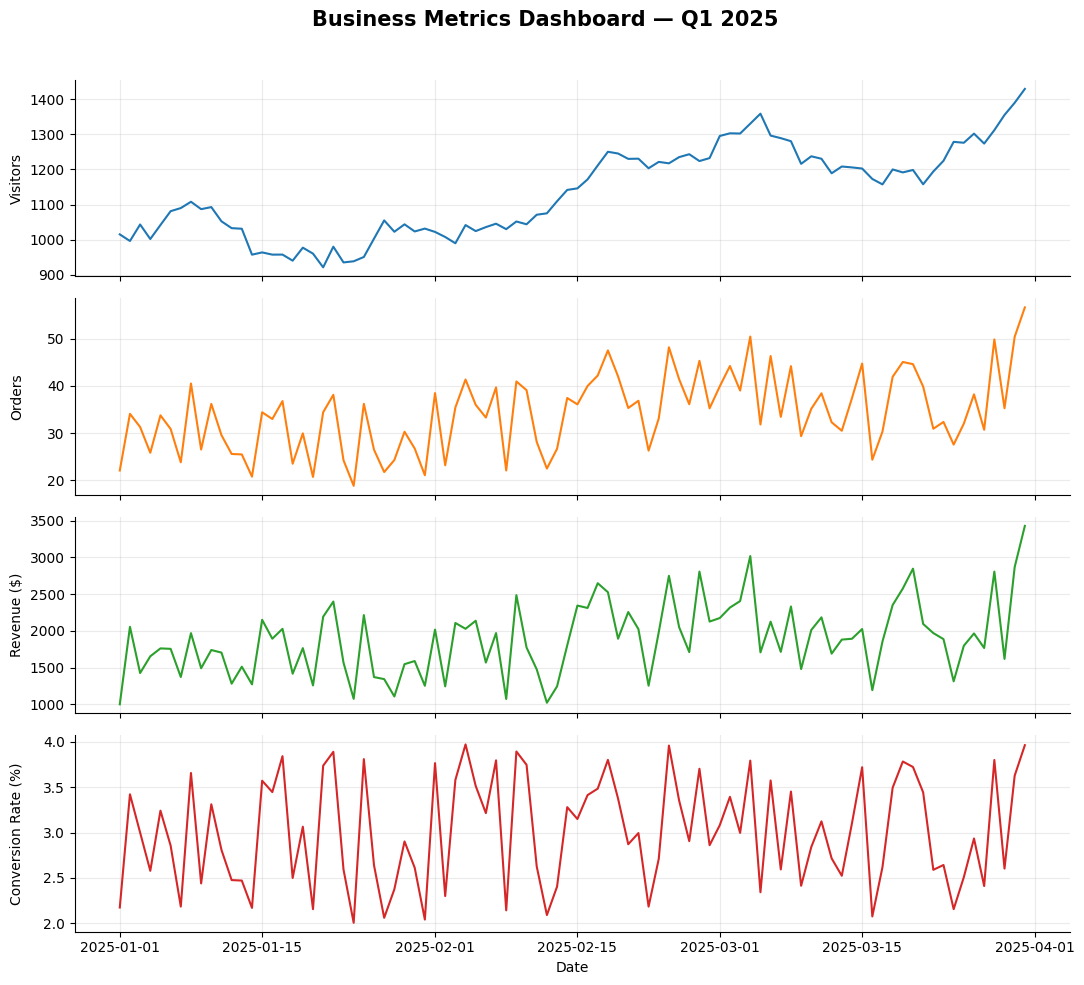

In [11]:
np.random.seed(110)
dates_dash = pd.date_range("2025-01-01", periods=90, freq="D")
visitors = 1000 + np.cumsum(np.random.normal(5, 30, 90))
orders = visitors * np.random.uniform(0.02, 0.04, 90)
revenue = orders * np.random.uniform(45, 65, 90)
conversion_rate = orders / visitors * 100

fig, axes = plt.subplots(4, 1, figsize=(11, 10), sharex=True)

metrics_to_plot = [
    (visitors, "Visitors", "tab:blue"),
    (orders, "Orders", "tab:orange"),
    (revenue, "Revenue ($)", "tab:green"),
    (conversion_rate, "Conversion Rate (%)", "tab:red"),
]

for ax, (values, label, color) in zip(axes, metrics_to_plot):
    ax.plot(dates_dash, values, color=color, linewidth=1.5)
    ax.set_ylabel(label, fontsize=10)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(True, alpha=0.25)

axes[-1].set_xlabel("Date")
fig.suptitle("Business Metrics Dashboard — Q1 2025", fontsize=15, fontweight="bold")
fig.align_ylabels(axes)   # aligns all y-axis labels vertically for a cleaner look
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


### Line-by-Line / Parameter Explanation
- `plt.subplots(4, 1, sharex=True)` — the exact "stacked subplots sharing an x-axis" alternative to twin axes recommended back in Chapter 35 — 4 different metrics with 4 completely different units/scales, each on its own clean y-axis, all visually time-aligned via the shared x-axis. This is a far safer choice than trying to cram all 4 onto one panel with multiple twin axes (which would compound Chapter 35's scaling-ambiguity risk 3 times over).
- `sharex=True` also has a practical UI benefit: only the bottom panel needs x-axis tick labels (Matplotlib automatically suppresses redundant tick labels on the shared upper panels) — reducing visual clutter.
- `fig.align_ylabels(axes)` — a polish detail: ensures all 4 y-axis labels sit at the same horizontal position regardless of how many digits each panel's tick labels happen to need, producing a cleaner, more aligned dashboard appearance.
- Per-panel spine removal + subtle grid directly reuses Chapter 12's minimalist styling pattern, applied consistently across all 4 panels via the loop.

### Interpretation
Reading down the stacked panels at the same x-position (date) lets a viewer directly assess co-movement: does a dip in Visitors around a specific date correspond to a dip in Orders and Revenue too, or does Conversion Rate move independently of Visitor volume? This kind of cross-metric, time-aligned reading is precisely what a single combined (or worse, twin-axis) chart would make much harder to do reliably.

### Common Mistakes
- Not using `sharex=True` for a multi-panel time-series dashboard — makes it much harder to precisely compare dates across panels, since each panel's x-axis might otherwise auto-scale slightly differently.
- Mismatched or missing per-panel labels — every panel needs its own clear y-axis label (with units) even though they share one x-axis, since only the y-axis reveals what each specific panel is showing.
- Cramming too many metrics into one dashboard (8+) — beyond roughly 4–6 stacked panels, a single dashboard becomes hard to take in as a whole; consider splitting into separate, more focused dashboards by theme.

### Best Practices
- Default to stacked subplots with `sharex=True` for any multi-metric time series dashboard, rather than twin axes, per Chapter 35's standing recommendation.
- Use `fig.align_ylabels()` for a small but noticeable polish improvement on any multi-panel figure.
- Cap a single dashboard at roughly 4–6 panels for genuine readability.

### Interview Insight
**Q: A stakeholder wants to see Revenue, Orders, Visitors, and Conversion Rate together, all in different units, over the same date range. What layout would you use, and why not put them all on one chart with multiple axes?**
A: A vertically stacked `plt.subplots(4, 1, sharex=True)` layout — one panel per metric, each with its own appropriately-scaled y-axis, sharing a single x-axis so dates stay precisely aligned for cross-metric comparison. Using multiple twin axes on one combined chart instead would compound the scaling-ambiguity and readability risks flagged in Chapter 35 for even a single extra axis — with four metrics of very different units on one panel, it would become both visually cluttered and genuinely misleading about relative magnitudes.

### Mini Exercise
Add a 5th panel for a new metric of your choice (e.g., a simulated "Average Order Value" = `revenue / orders`) to the existing 4-panel dashboard, adjusting `figsize` and the `plt.subplots(5, 1, ...)` call accordingly.

### Quiz (Chapter 73)
1. Why is `sharex=True` important for a multi-panel time-series dashboard?
2. Why is a stacked-subplot layout preferred over multiple twin axes for 3+ metrics of different units?
3. What does `fig.align_ylabels()` improve?


---
# CHAPTER 74 — PROFESSIONAL EDA NOTEBOOK (COMPLETE WORKED EXAMPLE)

## 1. Concept
This chapter assembles a genuinely complete, professional EDA notebook structure end-to-end — synthesizing nearly every technique from this course into the standard section order a real project deliverable would follow.

```
1. Business Understanding    7. Correlation
2. Dataset Overview          8. Business Insights
3. Data Quality              9. Next Steps
4. Missing Values
5. Univariate Analysis
6. Bivariate/Multivariate Analysis
```

## 2. Why It Matters
This structure — not any single chart — is the actual professional deliverable most Data Science roles produce weekly. Internalizing this end-to-end shape, and being able to execute it fluently on a new dataset, is the practical goal of the entire EDA-focused portion of this course (Chapters 41–74).

---
### 1. Business Understanding
> *(In a real notebook, this section is a markdown cell stating the business question in plain language — e.g., "Which customer attributes predict churn, and what actions could reduce it?" No code; established here as a reminder that every EDA notebook should start with the question, not the data.)*

### 2. Dataset Overview


In [12]:
np.random.seed(200)
n_final = 600
final_df = pd.DataFrame({
    "customer_id": np.arange(1, n_final + 1),
    "age": np.random.normal(41, 13, n_final).clip(18, 85).round(0),
    "monthly_charges": np.random.exponential(65, n_final).round(2),
    "tenure_months": np.random.exponential(28, n_final).round(1).clip(0, 72),
    "contract_type": np.random.choice(["Month-to-month", "One year", "Two year"], n_final, p=[0.55, 0.25, 0.20]),
    "support_calls": np.random.poisson(2, n_final),
    "churned": np.random.choice([0, 1], n_final, p=[0.76, 0.24]),
})
# Realistic missingness + a couple injected outliers, per Ch 68-69
final_df.loc[np.random.choice(final_df.index, 20, replace=False), "monthly_charges"] = np.nan
final_df.loc[np.random.choice(final_df.index, 3, replace=False), "age"] = 150   # impossible values

print(f"Shape: {final_df.shape}")
final_df.head(3)


Shape: (600, 7)


,customer_id,age,monthly_charges,tenure_months,contract_type,support_calls,churned
0,1,22.0,227.72,59.7,Month-to-month,1,0
1,2,66.0,162.56,36.8,One year,3,0
2,3,50.0,14.17,52.5,One year,2,0


### 3. Data Quality

In [13]:
print("Impossible age values (>100):", (final_df["age"] > 100).sum())
print("Duplicate customer_ids:", final_df["customer_id"].duplicated().sum())
# In a real notebook: fix/remove the impossible values before proceeding
final_df = final_df[final_df["age"] <= 100].copy()
print("Shape after removing impossible ages:", final_df.shape)


Impossible age values (>100): 3
Duplicate customer_ids: 0
Shape after removing impossible ages: (597, 7)


### 4. Missing Values

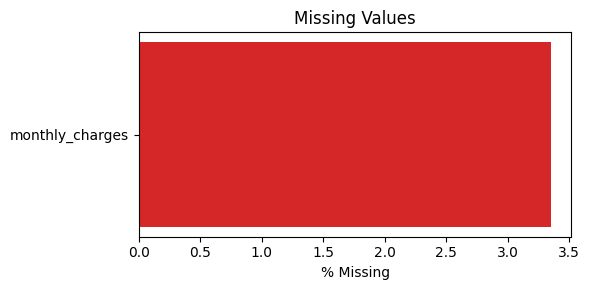

In [14]:
fig, ax = plt.subplots(figsize=(6, 3))
missing_pct = final_df.isna().mean() * 100
missing_pct = missing_pct[missing_pct > 0]
ax.barh(missing_pct.index, missing_pct.values, color="tab:red")
ax.set_xlabel("% Missing")
ax.set_title("Missing Values")
plt.tight_layout()
plt.show()


### 5. Univariate Analysis (Batch, Numerical + Categorical)

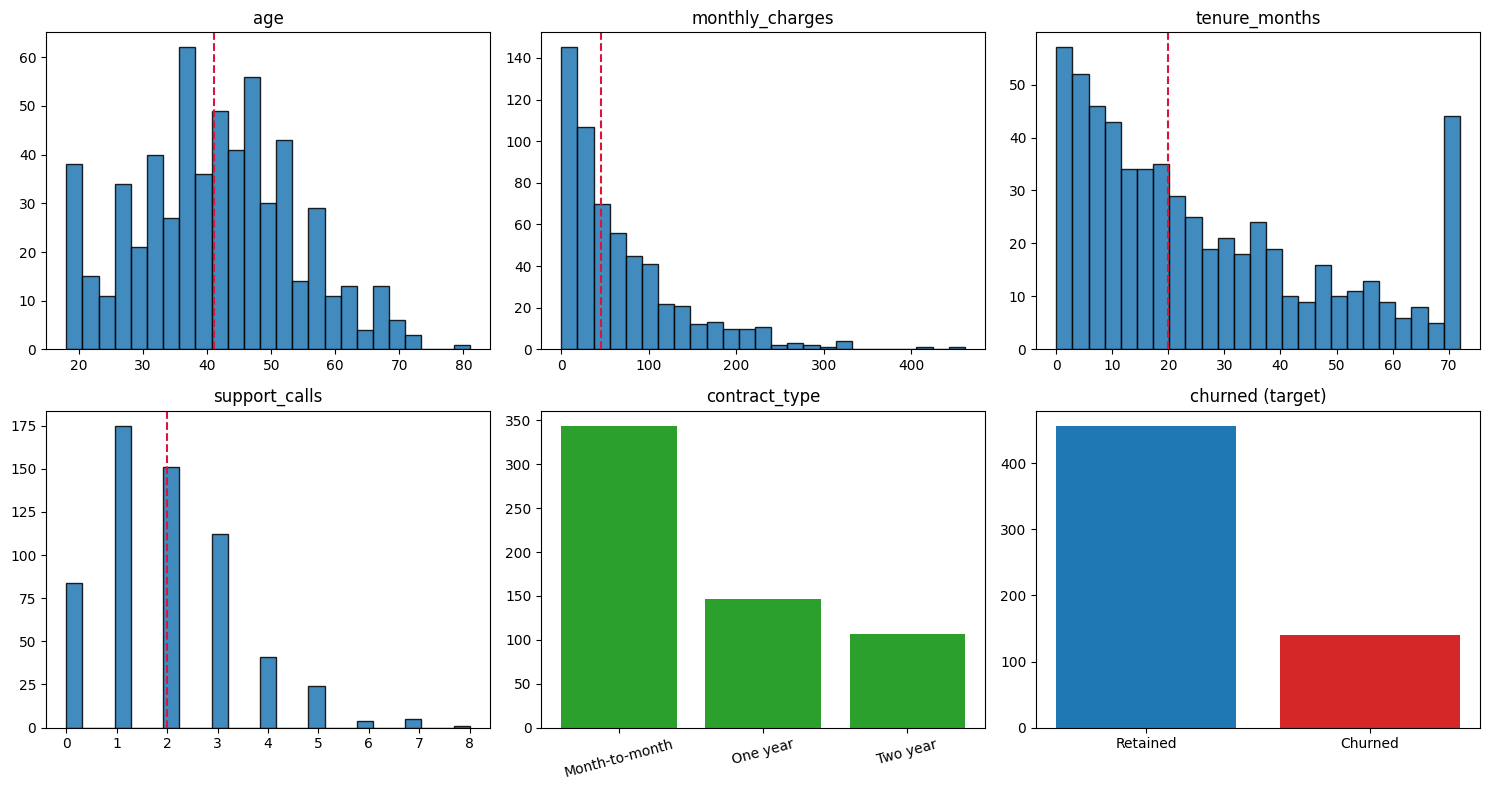

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

num_cols_final = ["age", "monthly_charges", "tenure_months", "support_calls"]
for ax, col in zip(axes.flatten()[:4], num_cols_final):
    ax.hist(final_df[col].dropna(), bins=25, color="tab:blue", edgecolor="black", alpha=0.85)
    ax.axvline(final_df[col].median(), color="crimson", linestyle="--")
    ax.set_title(col)

contract_counts = final_df["contract_type"].value_counts()
axes.flatten()[4].bar(contract_counts.index, contract_counts.values, color="tab:green")
axes.flatten()[4].set_title("contract_type")
axes.flatten()[4].tick_params(axis="x", rotation=15)

churn_counts_final = final_df["churned"].value_counts().sort_index()
axes.flatten()[5].bar(["Retained", "Churned"], churn_counts_final.values, color=["tab:blue", "tab:red"])
axes.flatten()[5].set_title("churned (target)")

plt.tight_layout()
plt.show()


### 6. Bivariate / Multivariate Analysis

/tmp/ipykernel_1959/3525409014.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0].boxplot(groups_churn, labels=["Retained", "Churned"])


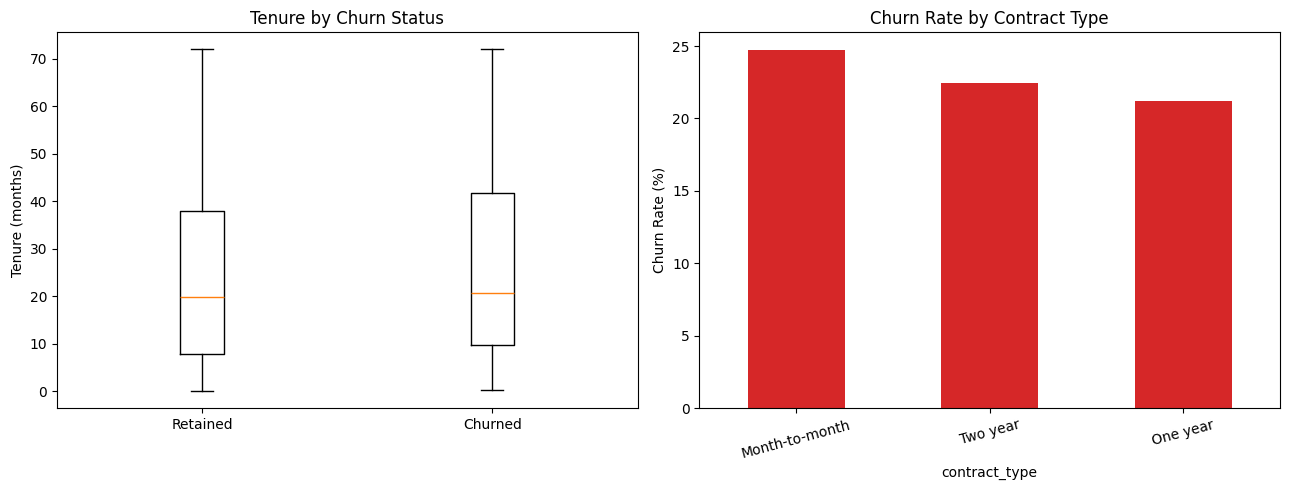

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

groups_churn = [final_df.loc[final_df["churned"] == c, "tenure_months"] for c in [0, 1]]
axes[0].boxplot(groups_churn, labels=["Retained", "Churned"])
axes[0].set_ylabel("Tenure (months)")
axes[0].set_title("Tenure by Churn Status")

churn_by_contract = pd.crosstab(final_df["contract_type"], final_df["churned"], normalize="index") * 100
churn_by_contract[1].sort_values(ascending=False).plot(kind="bar", ax=axes[1], color="tab:red")
axes[1].set_ylabel("Churn Rate (%)")
axes[1].set_title("Churn Rate by Contract Type")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()


### 7. Correlation

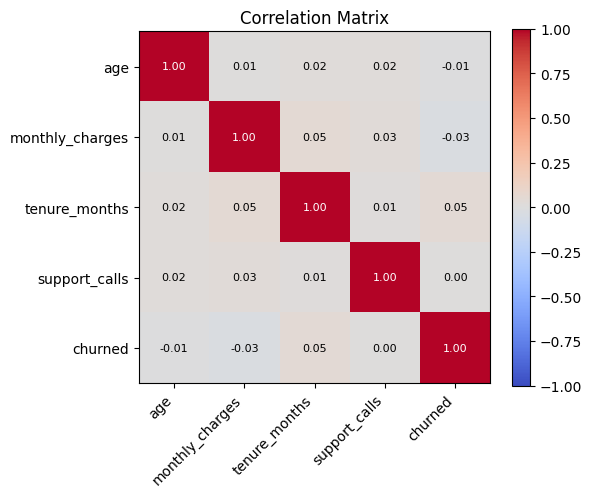

In [17]:
num_corr_df = final_df[num_cols_final + ["churned"]].corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(num_corr_df, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(num_corr_df.columns))); ax.set_yticks(range(len(num_corr_df.columns)))
ax.set_xticklabels(num_corr_df.columns, rotation=45, ha="right")
ax.set_yticklabels(num_corr_df.columns)
for i in range(len(num_corr_df)):
    for j in range(len(num_corr_df)):
        ax.text(j, i, f"{num_corr_df.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(num_corr_df.iloc[i, j]) > 0.5 else "black")
fig.colorbar(im, ax=ax)
ax.set_title("Correlation Matrix")
plt.tight_layout()
plt.show()


### 8. Business Insights *(markdown summary, no code)*
> Month-to-month contracts show a visibly higher churn rate than annual contracts — a direct, actionable finding (e.g., incentivize longer contract commitments). Tenure among retained customers skews higher than among churned customers, consistent with an expected "early-tenure customers churn more" pattern worth validating with a formal model.

### 9. Next Steps *(markdown summary, no code)*
> Build a churn classification model using Chapters 51–55's techniques; visualize its confusion matrix, ROC/PR curves, and feature importance; and run segment-level error analysis (Chapter 65) by contract type before deployment.

---

### Interview Insight
**Q: Walk me through the structure of a professional EDA notebook you'd hand to a stakeholder or teammate.**
A: Start with the business question in plain language, then dataset overview (shape, dtypes), data quality checks (impossible values, duplicates) with fixes applied and shown, missing-value visualization, batch univariate analysis for every numerical and categorical column, targeted bivariate/multivariate analysis addressing the specific business question, a correlation check with appropriate caveats, and finally a plain-language business insights summary plus concrete next steps — every visualization chosen deliberately per the chart-selection framework (Chapter 80) rather than habitually reused, and every step traceable and reproducible.

### Quiz (Chapter 74)
1. What are the 9 standard sections of a professional EDA notebook, in order?
2. Why does data quality checking (and fixing) happen *before* univariate analysis rather than after?
3. Why should "Business Insights" be written in plain language rather than just left as charts?


---
# CHAPTER 75 — MATPLOTLIB DEBUGGING

## Concept
A consolidated debugging reference: 15 problems this course has encountered piece by piece, now gathered as a single lookup table following the `Problem → Symptom → Cause → Diagnosis → Fix → Best Practice` structure.


### Problem 1 — Plot Not Showing
- **Symptom**: cell runs with no error, but no chart appears.
- **Cause**: non-interactive backend in a `.py` script without `plt.show()`, or a figure created and immediately closed.
- **Diagnosis**: check `matplotlib.get_backend()`; confirm `plt.show()` is called (or, in Jupyter, that the figure is the last statement/expression in the cell).
- **Fix**: add `plt.show()`; in scripts, confirm the backend supports a display.
- **Best Practice**: always end a plotting cell with `plt.show()` explicitly, even in Jupyter.

### Problem 2 — Wrong Shape
- **Symptom**: `ValueError` mentioning shape/dimension mismatch.
- **Cause**: passing a 2D array where a 1D array was expected, or vice versa.
- **Diagnosis**: `print(array.shape)` immediately before the plotting call.
- **Fix**: `.flatten()`, `.squeeze()`, or correct the upstream computation producing the wrong shape.
- **Best Practice**: print `.shape` as a standing habit before any first-time plotting call on new data.

### Problem 3 — x and y Length Mismatch
- **Symptom**: `ValueError: x and y must have the same first dimension`.
- **Cause**: (Chapter 4) one array filtered/sliced but not the other.
- **Diagnosis**: `print(len(x), len(y))`.
- **Fix**: ensure both arrays come from the same aligned filtering operation.
- **Best Practice**: filter a DataFrame first, then extract both columns from the *same* filtered result.

### Problem 4 — String Data Plotted Unexpectedly
- **Symptom**: a categorical column plotted with `ax.plot()` produces a nonsensical line or an error.
- **Cause**: (Chapter 43) using a line/scatter chart (built for ordered numeric data) on categorical strings.
- **Diagnosis**: check the column's dtype.
- **Fix**: switch to `ax.bar()` for categorical data.
- **Best Practice**: always confirm variable *type* (numeric vs categorical) before choosing chart type.

### Problem 5 — Dates Appear Incorrectly
- **Symptom**: x-axis shows raw numbers instead of dates, or dates in the wrong order.
- **Cause**: (Chapter 38) date column not actually converted to `datetime` dtype (still a string).
- **Diagnosis**: `df["date"].dtype` — should be `datetime64[ns]`, not `object`.
- **Fix**: `pd.to_datetime(df["date"])` before plotting.
- **Best Practice**: convert date columns to `datetime` immediately upon loading a dataset, not at plot time.

### Problem 6 — Labels Overlap
- **Symptom**: tick labels or subplot titles run into each other.
- **Cause**: (Chapters 11, 29) too many/too-long labels, or no layout management.
- **Diagnosis**: visually inspect; check label count and rotation.
- **Fix**: `ax.tick_params(rotation=45)`, `plt.tight_layout()`/`constrained_layout=True`.
- **Best Practice**: always apply layout management on any multi-subplot or dense-label figure by default.

### Problem 7 — Legend Is Missing
- **Symptom**: `ax.legend()` produces nothing, or a `UserWarning: No artists with labels found`.
- **Cause**: (Chapter 6) no plotting call included `label=`.
- **Diagnosis**: check every `ax.plot()`/`ax.bar()` call for a `label` argument.
- **Fix**: add `label=` to each relevant call, then re-call `.legend()`.
- **Best Practice**: add `label=` at the same time as writing the plotting call, not as an afterthought.

### Problem 8 — Colors Do Not Match Categories
- **Symptom**: two charts meant to represent the same categories use inconsistent colors across panels.
- **Cause**: relying on Matplotlib's automatic color cycle independently in each subplot/chart, rather than an explicit, shared color mapping.
- **Diagnosis**: compare the color-to-category mapping across the figures in question.
- **Fix**: build an explicit `dict` mapping category → color once, and reuse it in every chart referencing those categories (as done throughout Notebooks 5–8).
- **Best Practice**: define a shared color dictionary at the top of any notebook with recurring categories.

### Problem 9 — Plot Is Unreadable
- **Symptom**: too much visual clutter to extract any insight.
- **Cause**: too many series/categories/points on one Axes (Chapters 6, 9, 44, 70).
- **Diagnosis**: count distinct visual elements (lines, bars, colors) on the Axes.
- **Fix**: reduce via top-N + Other grouping, small multiples, or aggregation.
- **Best Practice**: apply the relevant chapter's "cap" guideline (≤6-8 lines, ≤10-15 categories, ≤3-4 overlaid encodings) proactively, not reactively.

### Problem 10 — Too Many Categories
- **Symptom**: a bar/pie chart with dozens of thin, unreadable slices/bars.
- **Cause**: (Chapters 24, 70) high-cardinality categorical variable plotted without aggregation.
- **Diagnosis**: `df[col].nunique()`.
- **Fix**: top-N + "Other" grouping (Chapter 70), or switch to `barh`.
- **Best Practice**: check `nunique()` before choosing a categorical chart type.

### Problem 11 — Outliers Destroy the Scale
- **Symptom**: most data compressed into a tiny sliver of the chart due to one or two extreme values.
- **Cause**: (Chapters 10, 68) auto-scaling stretched to accommodate an outlier/error.
- **Diagnosis**: `data.min()`, `data.max()`; check for impossible values.
- **Fix**: fix/remove genuine data errors first; otherwise consider a log scale (Chapter 36) or explicit `set_xlim`/`set_ylim` zoom (with a clear note that outliers are excluded from view).
- **Best Practice**: always run Chapter 68's outlier-triage step before finalizing any chart's axis range.

### Problem 12 — Subplots Have Incorrect Indexing
- **Symptom**: `IndexError: too many indices for array` on `axes[i, j]`.
- **Cause**: (Chapter 28) `plt.subplots()` returned a 1D array (because `nrows=1` or `ncols=1`), not 2D.
- **Diagnosis**: `print(axes.shape)`.
- **Fix**: index with `axes[i]` instead of `axes[i, j]` for 1D cases, or use `.flatten()`.
- **Best Practice**: always check `axes.shape` immediately after any non-square `plt.subplots()` call.

### Problem 13 — Unexpected Broadcasting
- **Symptom**: a plotted array has a surprising shape or values, with no explicit error.
- **Cause**: a NumPy broadcasting operation (upstream of plotting) silently combined arrays of incompatible-but-broadcastable shapes in an unintended way.
- **Diagnosis**: print shapes at each intermediate step of the array computation, not just the final plotted array.
- **Fix**: add explicit `.reshape()` or shape assertions at each step to catch the mismatch at its source.
- **Best Practice**: for any non-trivial NumPy computation feeding a plot, sanity-check shapes at each intermediate step, not only the plotting call itself.

### Problem 14 — NaN Values Affect Plots
- **Symptom**: unexpected gaps in a line plot, or `argmax`/statistics functions erroring or behaving oddly.
- **Cause**: (Chapters 33, 71) `NaN` values present in the plotted data.
- **Diagnosis**: `np.isnan(data).sum()` or `df[col].isna().sum()`.
- **Fix**: use NaN-safe functions (`np.nanargmax`, `np.nanmean`), or explicitly `.dropna()` where appropriate — decide deliberately, per Chapter 69, rather than by accident.
- **Best Practice**: always check for `NaN`s before computing any statistic or index-finding operation feeding into an annotation or summary.

### Problem 15 — Figure Saves Incorrectly
- **Symptom**: saved file has excess whitespace, wrong colors, or appears blank.
- **Cause**: (Chapter 31) missing `bbox_inches="tight"`, wrong `facecolor`, or `savefig()` called after the figure was cleared/closed.
- **Diagnosis**: inspect the actual saved file, not just the inline notebook render (they can differ).
- **Fix**: `bbox_inches="tight"`, explicit `facecolor`, and save **before** any `plt.close()`/`plt.show()` that might clear the figure in certain backends.
- **Best Practice**: always open and visually inspect a saved file at least once per project, rather than assuming it matches the inline preview.


In [18]:
# A consolidated demonstration: deliberately trigger and then fix Problem 12
fig, axes = plt.subplots(1, 3, figsize=(3, 2))   # nrows=1 -> axes is 1D
print("axes.shape:", axes.shape)   # confirms 1D, NOT (1, 3)-as-2D

try:
    axes[0, 0]   # this WILL raise -- demonstrating Problem 12
except IndexError as e:
    print("Reproduced Problem 12:", e)

# Correct fix: index with a single integer
axes[0].plot([1, 2, 3])
plt.close(fig)
print("Correct indexing (axes[0]) works fine.")


axes.shape: (3,)
Reproduced Problem 12: too many indices for array: array is 1-dimensional, but 2 were indexed
Correct indexing (axes[0]) works fine.


---

## END OF NOTEBOOK 8 — What You Should Now Be Able To Do
- Spot the visual signatures of data leakage and know what to investigate first when performance looks "too good."
- Set up visual data drift monitoring, including an explicit acceptable-range band to distinguish genuine drift from noise.
- Apply a disciplined outlier-triage workflow that separates impossible values from genuine rare events, rather than blanket-removing everything a box plot flags.
- Diagnose missingness patterns (not just counts), including cases where missingness itself is informative.
- Apply the top-N + "Other" pattern to any high-cardinality categorical variable.
- Build professional time-series charts with annotated anomalies and explicitly shaded missing/notable periods.
- Use rolling statistics (mean and std) to denoise a series and separately monitor its level and volatility.
- Build multi-panel, shared-x-axis time-series dashboards as the safe alternative to twin axes.
- Execute a complete, real, end-to-end professional EDA notebook from business question to insights and next steps.
- Diagnose and fix all 15 of the most common Matplotlib bugs from a single reference table.

## Before Moving to Notebook 9 (Chapters 76–85: Matplotlib Performance, Professional Visualization Design, Data Ink/Chart Junk, Misleading Visualizations, Chart Selection Framework, API Mastery, Parameter Mastery, Matplotlib Internals, Backends, Object-Oriented Matplotlib Mastery)
 